<a href="https://colab.research.google.com/github/manuelcorrea212/Fisica-Computacional/blob/main/Taller_10_Fisica_Computacional_Manuel_Correa_2417815_3146.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 5. Taller 10: librería de Fourier en Fortran y fenómeno de Gibbs

**Entrega:** viernes 4 de diciembre de 2026.

La DFT matricial del notebook 10a se convierte en una librería de Fortran, que se usa desde Python para estudiar el fenómeno de Gibbs. En la Semana 11 se presentará la FFT, que obtiene los mismos coeficientes mucho más rápido.

### A. Enunciado y requisitos

**Requisitos**

1. Las celdas del taller trabajan dentro de la carpeta `taller_fourier`, que crea la celda de la Parte B. En el repositorio, la carpeta `taller_fourier` contiene `modulo_fourier.f90` y este notebook.
2. El módulo se llama `fourier`, está en `modulo_fourier.f90` y se compila como la librería `fou`:
   `python -m numpy.f2py -c modulo_fourier.f90 -m fou`
3. El módulo contiene tres subrutinas que la celda de verificación llama directamente:

| Subrutina | Entradas | Salida | Uso desde Python |
|---|---|---|---|
| `matriz_dft` | `n` | `w(n,n)`, complejo: $W_{jk} = e^{-2\pi i\,(j-1)(k-1)/n}$ | `fou.fourier.matriz_dft(n)` |
| `dft` | `n`; `x(n)`, complejo | `xf(n)` $= W\,x$ | `fou.fourier.dft(x)` |
| `idft` | `n`; `xf(n)`, complejo | `x(n)` $= W^H\,xf/n$ | `fou.fourier.idft(xf)` |

   Los índices de Fortran empiezan en 1: el elemento `w(j,k)` corresponde a $W_{j-1,\,k-1}$ del notebook 10a.
4. `dft` e `idft` obtienen $W$ llamando a `matriz_dft` y calculan el producto con `matmul`. La inversa usa la transpuesta conjugada, no un sistema de ecuaciones.
5. Se usan `complex(8)` y `real(8)`. La matriz $W$ dentro de `dft` e `idft` debe ser **dinámica** (`allocatable`, Capítulo 3): con $n = 1024$ ocupa 16 MiB, y como arreglo automático puede desbordar la memoria de pila. El módulo no usa `stop`.

**Qué se entrega**

- En la carpeta del repositorio: `modulo_fourier.f90` y este notebook, con la celda de verificación en 3 de 3 PASS y las respuestas de la sección D en celdas Markdown al final.
- En Moodle: el reporte de una página y el enlace a la carpeta.

<div style="border-left: 5px solid #B02A20; background-color: #FBEDEC; padding: 10px 14px; margin: 8px 0;">

**No está permitido** usar `np.fft`, `scipy.fft` ni la función `matriz_dft` de Python de este notebook dentro de las actividades. Las transformadas se calculan con su librería de Fortran. `np.fft.fft` solo puede usarse para comparar, en la actividad 1.

</div>

<div style="border-left: 5px solid #2E7D32; background-color: #EAF5EA; padding: 10px 14px; margin: 8px 0;">

**Precisión del exponente.** El ángulo $2\pi (j-1)(k-1)/n$ crece hasta valores del orden de $2\pi n$. Como $e^{-2\pi i\,m/n}$ solo depende del residuo de $m$ al dividir por $n$, conviene usar `mod((j-1)*(k-1), n)` en lugar de $(j-1)(k-1)$: el ángulo queda en $[0, 2\pi)$ y el error de redondeo no crece con $n$.

</div>

### B. Parte Fortran: la librería

Ejecute primero la celda siguiente, que crea la carpeta `taller_fourier` y la deja como carpeta de trabajo. Después escriba `modulo_fourier.f90` y compílelo. Recuerde de la Semana 9: después de cada recompilación, **reinicie el entorno** y ejecute de nuevo la celda de preparación y esta celda.

In [1]:
# Carpeta de trabajo del taller: aquí se escriben, compilan, importan y verifican los archivos
import os, sys
CARPETA = "taller_fourier"
if os.path.basename(os.getcwd()) != CARPETA:     # evita crear taller_fourier/taller_fourier
    os.makedirs(CARPETA, exist_ok=True)
    os.chdir(CARPETA)
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())               # import fou busca la librería aquí
print("Carpeta de trabajo:", os.getcwd())

Carpeta de trabajo: /content/taller_fourier


In [2]:
# Compila la librería "fou" (ejecute esta celda cuando su archivo esté listo)
!python -m numpy.f2py -c modulo_fourier.f90 -m fou 2>&1 | tail -n 3

              x = idft(xf,[n])
    Wrote C/API module "fou" to file "./foumodule.c"
    Fortran 90 wrappers are saved to "./fou-f2pywrappers2.f90"


### C. Parte Python: uso de la librería

Ejecute las actividades en las celdas siguientes. Cada una indica qué debe obtener.

**Actividad 1. Prueba de la librería.** Importe `fou` e imprima la documentación de `dft`. Con su librería, obtenga:

- la matriz `matriz_dft(4)`, que debe coincidir con la del notebook 10a;
- la DFT de $x = (1, 2, 3, 4)$, que debe ser $(10,\ -2+2i,\ -2,\ -2-2i)$;
- para un vector aleatorio de 64 elementos, el error máximo de `dft` frente a `np.fft.fft`, el de `idft(dft(x))` frente a $x$, y el de $W W^H$ frente a $64\,I$. Los tres deben ser menores que $10^{-10}$.

**Actividad 2. Espectro de la función caja.** Construya la caja de $N = 1024$ muestras: 312 ceros, 400 unos y 312 ceros. Es la misma proporción de la caja de la sección 4, con más resolución. Su DFT tiene forma analítica:

$$|X_0| = L, \qquad |X_j| = \left|\frac{\sin(\pi j L/N)}{\sin(\pi j/N)}\right| \quad (j \neq 0),$$

con $L = 400$, el número de unos. Obtenga la gráfica de $|X_j|$ para $j = 0, \dots, N/2$, en escala logarítmica, junto con la fórmula, y el error máximo entre las dos, que debe ser menor que $10^{-8}$.

**Actividad 3. Filtro pasa-bajos.** Para $K = 8, 16, 32, 64$, conserve los coeficientes con $|j| \le K$ (sección 4), anule los demás y reconstruya la señal con `idft`. Obtenga:

- la parte imaginaria máxima de cada reconstrucción, que debe ser menor que $10^{-10}$;
- una figura con la caja y las cuatro reconstrucciones, ampliada alrededor del primer salto ($250 \le k \le 400$).

**Actividad 4. Medición del fenómeno de Gibbs.** El primer salto de la caja está entre las muestras $k = 311$ y $k = 312$ (numeración de Python), es decir, en $k_s = 311.5$. Para cada $K$ de la actividad 3, obtenga una tabla con:

- el valor máximo $s_{\max}$ de la reconstrucción y el sobrepaso $(s_{\max} - 1)\times 100\,\%$ (el salto es de 0 a 1);
- la distancia $d$ entre la posición del máximo y el salto más cercano, y el producto $K\,d$;
- el error cuadrático medio $E_K = \sqrt{\frac{1}{N}\sum_k (s_k - x_k)^2}$ y la razón $E_K/E_{2K}$.

Debe obtener sobrepasos entre 7.5 % y 9 % para todos los $K$, productos $K\,d$ cercanos a $N/2 = 512$ y razones $E_K/E_{2K}$ cercanas a $\sqrt{2} \approx 1.41$.

In [3]:
# Actividad 1

In [4]:
# Actividad 2

In [5]:
# Actividad 3

In [6]:
# Actividad 4

### D. Preguntas de interpretación

Responda en celdas Markdown al final de este notebook, con los números de sus resultados:

1. **Simetría.** ¿Por qué la reconstrucción de la actividad 3 sale real? ¿Qué pasaría si se anularan solo los últimos coeficientes del arreglo, como advierte la sección 4?
2. **Gibbs.** Según su tabla de la actividad 4, ¿el sobrepaso disminuye al aumentar $K$? ¿Qué cantidades sí cambian, y cómo? Compare su sobrepaso con el 8.95 % de la serie de Fourier.
3. **Costo.** ¿Cuántas multiplicaciones complejas hace su subrutina `dft` con $N = 1024$? ¿Por qué factor se multiplicaría el tiempo si $N$ se duplicara?

### SOLUCION

#### PREGUNTA B

In [7]:
# 1. Instalar meson y ninja (herramientas de compilación que f2py necesita)
!pip install -q meson ninja

# 2. Instalar el compilador de Fortran
!apt-get install -y -q gfortran

# 3. Verificar que las herramientas están en el PATH
!which meson ninja gfortran

Reading package lists...
Building dependency tree...
Reading state information...
gfortran is already the newest version (4:13.2.0-7ubuntu1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
/usr/local/bin/meson
/usr/local/bin/ninja
/usr/bin/gfortran


In [8]:
# Carpeta de trabajo del taller: aquí se escriben, compilan, importan y verifican los archivos
import os, sys
CARPETA = "taller_fourier"
if os.path.basename(os.getcwd()) != CARPETA:     # evita crear taller_fourier/taller_fourier
    os.makedirs(CARPETA, exist_ok=True)
    os.chdir(CARPETA)
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())               # import fou busca la librería aquí
print("Carpeta de trabajo:", os.getcwd(), "| Archivos:", os.listdir("."))

Carpeta de trabajo: /content/taller_fourier | Archivos: ['modulo_fourier.f90', 'fou.cpython-313-x86_64-linux-gnu.so']


In [9]:
%%writefile modulo_fourier.f90
! ============================================================
! Módulo:    fourier
! Propósito: matriz de Fourier, DFT e inversa (IDFT) usando
!            producto matriz-vector y transpuesta conjugada.

module fourier
  implicit none
  real(8), parameter :: pi = 4.0d0 * atan(1.0d0)

contains

  ! ----------------------------------------------------------
  ! matriz_dft: construye la matriz de Fourier W de n x n
  !             con W(j,k) = exp(-2*pi*i*(j-1)*(k-1)/n)

  subroutine matriz_dft(n, w)
    integer,    intent(in)  :: n
    complex(8), intent(out) :: w(n, n)
    integer :: j, k, m
    real(8) :: angulo

    do k = 1, n
       do j = 1, n
          m = mod((j - 1) * (k - 1), n)
          angulo = -2.0d0 * pi * dble(m) / dble(n)
          w(j, k) = cmplx(cos(angulo), sin(angulo), kind=8)
       end do
    end do
  end subroutine matriz_dft

  ! ----------------------------------------------------------
  ! dft: transformada discreta de Fourier xf = W x

  subroutine dft(n, x, xf)
    integer,    intent(in)  :: n
    complex(8), intent(in)  :: x(n)
    complex(8), intent(out) :: xf(n)
    complex(8), allocatable :: w(:, :)

    allocate(w(n, n))
    call matriz_dft(n, w)
    xf = matmul(w, x)
    deallocate(w)
  end subroutine dft

  ! ----------------------------------------------------------
  ! idft: transformada inversa de Fourier x = W^H xf / n

  subroutine idft(n, xf, x)
    integer,    intent(in)  :: n
    complex(8), intent(in)  :: xf(n)
    complex(8), intent(out) :: x(n)
    complex(8), allocatable :: w(:, :)

    allocate(w(n, n))
    call matriz_dft(n, w)
    x = matmul(conjg(transpose(w)), xf) / dble(n)
    deallocate(w)
  end subroutine idft

end module fourier

Overwriting modulo_fourier.f90


In [10]:
# Compila la librería "fou" y copia el archivo binario generado al directorio padre (/content) para poder importarlo sin cambiar de directorio
!python -m numpy.f2py -c modulo_fourier.f90 -m fou 2>&1 | tail -n 3


              x = idft(xf,[n])
    Wrote C/API module "fou" to file "./foumodule.c"
    Fortran 90 wrappers are saved to "./fou-f2pywrappers2.f90"


#### PREGUNTA C

##### ACTIVIDAD 1

In [11]:

import numpy as np
import fou

print(fou.fourier.dft.__doc__)

# 1. Matriz de Fourier 4x4
W4_lib = fou.fourier.matriz_dft(4)
W4_ref = np.array([
    [1,   1,   1,  1],
    [1, -1j,  -1, 1j],
    [1,  -1,   1, -1],
    [1,  1j,  -1, -1j],
], dtype=complex)
print("matriz_dft(4):\n", W4_lib)
print("Error máx matriz_dft(4):", np.max(np.abs(W4_lib - W4_ref)))

# 2. DFT de x = (1, 2, 3, 4)
x4 = np.array([1.0, 2.0, 3.0, 4.0], dtype=complex)
X4 = fou.fourier.dft(x4)
X4_ref = np.array([10.0, -2.0 + 2.0j, -2.0, -2.0 - 2.0j], dtype=complex)
print("\ndft([1, 2, 3, 4]):", X4)
print("Error máx dft([1, 2, 3, 4]):", np.max(np.abs(X4 - X4_ref)))

# 3. Vector aleatorio complejo de 64 elementos
rng = np.random.default_rng(2026)
x64 = rng.normal(size=64) + 1j * rng.normal(size=64)
X64 = fou.fourier.dft(x64)
x64_rec = fou.fourier.idft(X64)
W64 = fou.fourier.matriz_dft(64)

err_fft = np.max(np.abs(X64 - np.fft.fft(x64)))
err_rec = np.max(np.abs(x64_rec - x64))
err_ort = np.max(np.abs(W64 @ W64.conj().T - 64.0 * np.eye(64)))

print("\nError máx |dft(x) - fft(x)|:", err_fft)
print("Error máx |idft(dft(x)) - x|:", err_rec)
print("Error máx |W W^H - 64 I|:", err_ort)

xf = dft(x,[n])

Wrapper for ``dft``.

Parameters
----------
x : input rank-1 array('D') with bounds (n)

Other Parameters
----------------
n : input int, optional
    Default: shape(x, 0)

Returns
-------
xf : rank-1 array('D') with bounds (n)

matriz_dft(4):
 [[ 1.0000000e+00-0.0000000e+00j  1.0000000e+00-0.0000000e+00j
   1.0000000e+00-0.0000000e+00j  1.0000000e+00-0.0000000e+00j]
 [ 1.0000000e+00-0.0000000e+00j  6.1232340e-17-1.0000000e+00j
  -1.0000000e+00-1.2246468e-16j -1.8369702e-16+1.0000000e+00j]
 [ 1.0000000e+00-0.0000000e+00j -1.0000000e+00-1.2246468e-16j
   1.0000000e+00-0.0000000e+00j -1.0000000e+00-1.2246468e-16j]
 [ 1.0000000e+00-0.0000000e+00j -1.8369702e-16+1.0000000e+00j
  -1.0000000e+00-1.2246468e-16j  6.1232340e-17-1.0000000e+00j]]
Error máx matriz_dft(4): 1.8369701987210297e-16

dft([1, 2, 3, 4]): [10.+0.00000000e+00j -2.+2.00000000e+00j -2.-7.34788079e-16j
 -2.-2.00000000e+00j]
Error máx dft([1, 2, 3, 4]): 7.347880794884119e-16

Error máx |dft(x) - fft(x)|: 1.517

##### ACTIVIDAD 2

Error máximo frente a la fórmula analítica: 1.007e-13


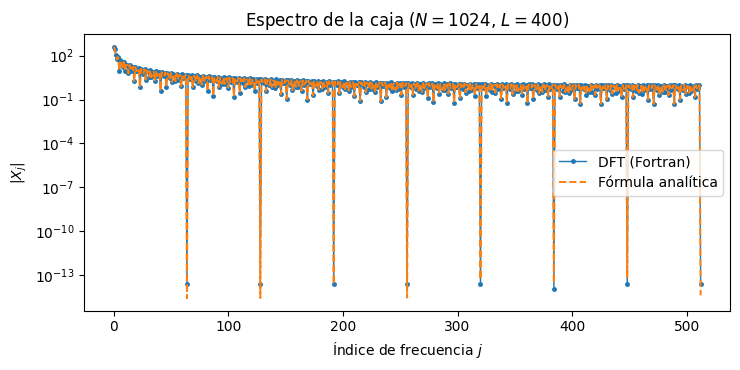

In [13]:

import numpy as np
import matplotlib.pyplot as plt
import fou

# Definimos las variables de colores requeridos
AZUL = "#1f77b4"
DORADO = "#ff7f0e"

N = 1024
L = 400
caja = np.concatenate([np.zeros(312), np.ones(L), np.zeros(312)]).astype(complex)

X_caja = fou.fourier.dft(caja)
j = np.arange(N // 2 + 1)

# Fórmula analítica: |X_0| = L, y para j > 0: |sin(pi*j*L/N)/sin(pi*j/N)|
esp_num = np.abs(X_caja[j])
esp_ana = np.empty_like(esp_num)
esp_ana[0] = L
esp_ana[1:] = np.abs(np.sin(np.pi * j[1:] * L / N) / np.sin(np.pi * j[1:] / N))

err_caja = np.max(np.abs(esp_num - esp_ana))
print(f"Error máximo frente a la fórmula analítica: {err_caja:.3e}")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.semilogy(j, esp_num, "o-", color=AZUL, ms=2.5, lw=1.0, label="DFT (Fortran)")
ax.semilogy(j, esp_ana, "--", color=DORADO, lw=1.4, label="Fórmula analítica")
ax.set(
    title=f"Espectro de la caja ($N={N}$, $L={L}$)",
    xlabel="Índice de frecuencia $j$",
    ylabel=r"$|X_j|$",
)
ax.legend()
plt.tight_layout()
plt.show()

##### ACTIVIDAD 3

K =  8 -> máx |Im(s)| = 4.078e-16
K = 16 -> máx |Im(s)| = 5.354e-16
K = 32 -> máx |Im(s)| = 5.825e-16
K = 64 -> máx |Im(s)| = 7.186e-16


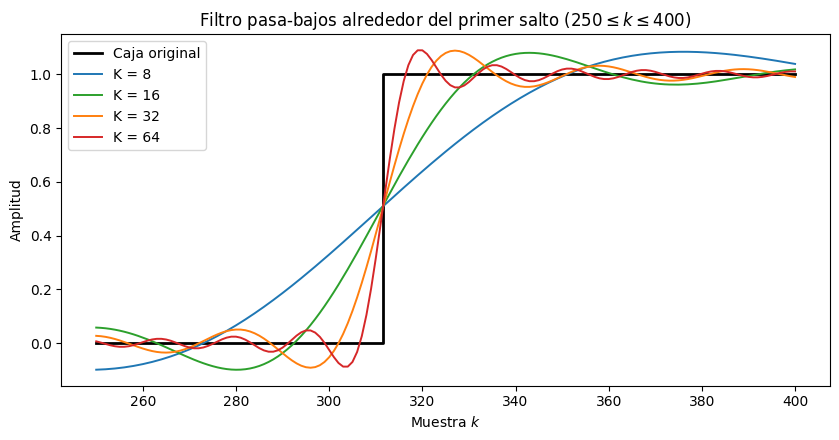

In [17]:

Ks = [8, 16, 32, 64]
k = np.arange(N)
reconstrucciones = {}

for K in Ks:
    mascara = (k <= K) | (k >= N - K)
    X_filtrado = np.where(mascara, X_caja, 0.0 + 0.0j)
    s_rec = fou.fourier.idft(X_filtrado)
    reconstrucciones[K] = s_rec.real
    max_imag = np.max(np.abs(s_rec.imag))
    print(f"K = {K:2d} -> máx |Im(s)| = {max_imag:.3e}")

# Definimos las variables de color faltantes para la gráfica
VERDE = "#2ca02c"
ROJO = "#d62728"

fig, ax = plt.subplots(figsize=(8.5, 4.5))
zoom = (k >= 250) & (k <= 400)
ax.step(k[zoom], caja[zoom].real, where="mid", color="k", lw=2.0, label="Caja original")

colores_K = [AZUL, VERDE, DORADO, ROJO]
for K, col in zip(Ks, colores_K):
    ax.plot(k[zoom], reconstrucciones[K][zoom], lw=1.4, color=col, label=f"K = {K}")

ax.set(
    title="Filtro pasa-bajos alrededor del primer salto ($250 \\leq k \\leq 400$)",
    xlabel="Muestra $k$",
    ylabel="Amplitud",
)
ax.legend()
plt.tight_layout()
plt.show()

##### ACTIVIDAD 4

In [18]:
# Actividad 4
x_real = caja.real
saltos = np.array([311.5, 711.5])
errores_rms = {}
datos_tabla = []

for K in Ks:
    s_k = reconstrucciones[K]
    s_max = np.max(s_k)
    sobrepaso_pct = (s_max - 1.0) * 100.0
    k_max = np.argmax(s_k)
    d = np.min(np.abs(k_max - saltos))
    Kd = K * d
    ek = np.sqrt(np.mean((s_k - x_real) ** 2))
    errores_rms[K] = ek
    datos_tabla.append((K, s_max, sobrepaso_pct, d, Kd, ek))

print(f"{'K':>3} | {'s_max':>8} | {'Sobrepaso [%]':>13} | {'d':>6} | {'K·d':>7} | {'E_K':>10} | {'E_K/E_2K':>10}")
print("-" * 76)
for K, s_max, sobrepaso_pct, d, Kd, ek in datos_tabla:
    razon_str = f"{ek / errores_rms[2*K]:10.4f}" if (2 * K) in errores_rms else f"{'---':>10}"
    print(f"{K:3d} | {s_max:8.5f} | {sobrepaso_pct:12.3f}% | {d:6.2f} | {Kd:7.1f} | {ek:10.6f} | {razon_str}")

  K |    s_max | Sobrepaso [%] |      d |     K·d |        E_K |   E_K/E_2K
----------------------------------------------------------------------------
  8 |  1.08369 |        8.369% |  64.50 |   516.0 |   0.112168 |     1.4241
 16 |  1.07978 |        7.978% |  31.50 |   504.0 |   0.078765 |     1.4241
 32 |  1.08801 |        8.801% |  15.50 |   496.0 |   0.055309 |     1.3992
 64 |  1.08911 |        8.911% |   8.50 |   544.0 |   0.039530 |        ---


#### PREGUNTA D

##### 1. Simetria
¿Porque la reconstruccion de la actividad 3 sale real?
- Porque la señal original es decir, la funcion caja es real, por lo tanto su transformada discreta de fourier posee simetria conjugada:$X_{N-j} = X_j^*$ para $j = 1, \dots, N/2 - 1$ (y $X_0$, $X_{N/2}$ son reales). Al aplicar el filtro de pasa*bajos conservando unicamente los indices con $\vert{}j\vert{} \le K$, es decir frecuencias positivas bajas; Junto con los ultimos  $N - K \le k \le N - 1$, frecuencias negativas bajas.
Cada coeficiente $X_j$ conserva su pareja conjugada $X_{N-j}$, al sumar pares de oscilaciones conjugadas $X_j e^{2\pi i j k/N} + X_j^* e^{-2\pi i j k/N} = 2\operatorname{Re}(X_j e^{2\pi i j k/N})$, las partes imaginarias se cancelan, dejando un redondeo de un punto flotante $\max \vert{}\operatorname{Im}(s)\vert{} = 4.078\times 10^{-16}$ para $K=8$, $5.354\times 10^{-16}$ para $K=16$, $5.825\times 10^{-16}$ para $K=32$ y $7.186\times 10^{-16}$ para $K=64$.

¿Que pasaria si se anularan solo los ultimos coeficientes del arreglo?
- En el orden de la DFT, la segunda mitad del arreglo  ($N/2 < k \le N-1$) no contiene las frecuencias altas, sino las frecuencias negativas ($f_k = (k - N)\Delta f$). Por lo tanto, si se anularan solo los ultimos coeficientes, por ejemplo poniendo a 0 todos lo indices  $k > K$ y dejando únicamente $0 \le k \le K$. Se destruiria la simetria conjugada, desaparecerian las frecuencias negativas que cancelan las partes imaginarias de las positivas y por ende la señal reconstruida no seria rea, tambien perdiendo la mitad de la amplitud de cada componente oscilatorio.

##### 2. Fenomeno de Gibbs
¿El sobrepaso disminuye al aumentar k?
- No, segun los resultados de la actividad 4, el sobrepaso se mantendra constante entre  $8\%$–$9\%$ sin tender a cero al aumentar el número de modos conservado.

¿Que cantidades si cambian y como?
- La distancia d del primer maximo al salto: isminuye de forma inversamente proporcional a $K$ ($d \propto 1/K$), pasando de $d = 64.50$ ($K=8$), a $31.50$ ($K=16$), $15.50$ ($K=32$) y $8.50$ ($K=64$). De tal manera que el producto $K \cdot d$ se mantiene constante cerca de $N/2 = 512$. Es decir el pico de sobrepaso no desaparece, sino que se comprime cada vez más cerca de la discontinuidad.

El error cuadratico medio $E_K$:
- Disminuye con  $K$ ($0.112168 \to 0.078765 \to 0.055309 \to 0.039530$).Al duplicar $K$, la razón $E_K / E_{2K}$ vale $1.4241$, $1.4241$ y $1.3992$, valores muy cercanos a $\sqrt{2} \approx 1.4142$, lo cual confirma que el error global cae como $E_K \propto K^{-1/2}$ debido a que la región oscilatoria se estrecha en proporción a $1/K$.

Comparacion con el $8.95\%$ de la serie de Fourier:
- Al aumentar $K$, el sobrepaso discreto converge hacia el valor asintotico clasico de Gibbs para una discontinuidad de salto en la serie de Fourier continua $\approx 8.95\%$. Pasa de $8.369\%$ $K=8$ a $8.801\%$ $K=32$ y alcanza $8.911\%$ para $K=64$, quedando cerca, apenas 0.039 puntos porcentuales del limite teorico continuo.

##### 3. Costo conductual
¿Cuantas multiplicaciones complejas hace la subrutina dft con $N = 1024$?
- La subrutina dft calcula el producto matriz-vector $X = W x$, donde  $W \in \mathbb{C}^{N \times N}$ y $x \in \mathbb{C}^N$. Para calcular cada uno de los $N$ elementos de $X$ se realizan $N$ multiplicaciones complejas, lo que da un total de: $N^2 = 1024^2 = 1\,048\,576 \text{ multiplicaciones complejas}$.

¿Por que factor se multiplicaria el tiempo si N se duplica?
- Dado que el costo de DFT matricial escala cuadraticamente como $\mathcal{O}(N^2)$, si $N$ se duplica ($N \to 2N = 2048$). El numero de operaciones y la memoria requerida por la matriz W se se multiplican por un factor de $4$, es decir, el tiempo de ejecucion cuadruplica a $4\,194\,304$.


#### PREGUNTA E. Verificación

La celda siguiente **no debe modificarse**. Importa su librería y la prueba con casos de resultado conocido. Si recompiló la librería, reinicie el entorno antes de ejecutarla. El taller exige los tres PASS.

In [19]:
# ==================== VERIFICACIÓN DEL TALLER 10 (no modificar) ====================
import os, sys, glob
import numpy as np

resultados = []
def caso(nombre, funcion):
    try:
        detalle = funcion()
        ok = True
    except Exception as e:
        ok, detalle = False, str(e)
    resultados.append(ok)
    print(f"[{'PASS' if ok else 'FAIL'}] {nombre}" + (f" -> {detalle}" if detalle else ""))

# La verificación siempre trabaja dentro de la carpeta del taller
CARPETA = "taller_fourier"
if os.path.basename(os.getcwd()) != CARPETA:
    if not os.path.isdir(CARPETA):
        raise SystemExit(f"No existe la carpeta {CARPETA}: ejecute la celda de la Parte B.")
    os.chdir(CARPETA)
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("Verificando en:", os.getcwd(), "\n")

def libreria():
    if not os.path.isfile("modulo_fourier.f90"):
        raise ValueError(f"no existe modulo_fourier.f90 en {CARPETA}")
    so = glob.glob("fou.*.so") + glob.glob("fou.*.pyd")
    if not so:
        raise ValueError(f"no se encontró la librería fou en {CARPETA}; compile con F2PY")
    so = max(so, key=os.path.getmtime)                # la más reciente, si hay varias
    if os.path.getmtime(so) < os.path.getmtime("modulo_fourier.f90"):
        raise ValueError("la librería es anterior a modulo_fourier.f90; recompile y reinicie")
    import fou
    if os.path.abspath(fou.__file__) != os.path.abspath(so):
        raise ValueError(f"la librería cargada es {fou.__file__}, no la de {CARPETA}; reinicie el entorno")
    if not hasattr(fou, "fourier"):
        raise ValueError("la librería no contiene el módulo fourier")
    return fou.fourier

def dft_directa(x):
    """DFT por la definición, como suma doble (referencia de la verificación)."""
    N = len(x); k = np.arange(N)
    return np.array([np.sum(x*np.exp(-2j*np.pi*j*k/N)) for j in range(N)])

def c1():
    lib = libreria()
    W4 = np.array([[1, 1, 1, 1], [1, -1j, -1, 1j], [1, -1, 1, -1], [1, 1j, -1, -1j]])
    if np.max(np.abs(lib.matriz_dft(4) - W4)) > 1e-12:
        raise ValueError("matriz_dft(4) no es la matriz de Fourier de 4 x 4")
    X = lib.dft([1.0, 2.0, 3.0, 4.0])
    if np.max(np.abs(X - np.array([10, -2 + 2j, -2, -2 - 2j]))) > 1e-12:
        raise ValueError("dft([1, 2, 3, 4]) no da (10, -2+2i, -2, -2-2i)")
    return "matriz de 4 x 4 y DFT de (1, 2, 3, 4) correctas"

def c2():
    lib = libreria()
    x = np.random.default_rng(11).normal(size=64) + 1j*np.random.default_rng(12).normal(size=64)
    if np.max(np.abs(lib.dft(x) - dft_directa(x))) > 1e-10:
        raise ValueError("dft no coincide con la definición para un vector complejo de 64 elementos")
    if np.max(np.abs(lib.idft(lib.dft(x)) - x)) > 1e-12:
        raise ValueError("idft(dft(x)) no recupera x")
    W = lib.matriz_dft(64)
    if np.max(np.abs(W @ W.conj().T - 64*np.eye(64))) > 1e-10:
        raise ValueError("W W^H no es 64 I")
    return "dft, idft y ortogonalidad correctas para N = 64"

def c3():
    lib = libreria()
    N, L, K = 1024, 400, 64
    caja = np.zeros(N); caja[312:712] = 1.0
    X = lib.dft(caja)
    j = np.arange(1, N//2 + 1)
    if np.max(np.abs(np.abs(X[1:N//2 + 1]) - np.abs(np.sin(np.pi*j*L/N)/np.sin(np.pi*j/N)))) > 1e-8:
        raise ValueError("el espectro de la caja no coincide con la fórmula analítica")
    k = np.arange(N)
    s = lib.idft(np.where((k <= K) | (k >= N - K), X, 0))
    if np.max(np.abs(s.imag)) > 1e-10:
        raise ValueError("la reconstrucción filtrada no es real")
    smax = s.real.max()
    d = np.min(np.abs(np.argmax(s.real) - np.array([311.5, 711.5])))
    if not (1.085 < smax < 1.093) or not (400 < K*d < 600):
        raise ValueError(f"Gibbs con K = 64 fuera de lo esperado: s_max = {smax:.4f}, K d = {K*d:.0f}")
    return f"espectro de la caja correcto; Gibbs con K = 64: s_max = {smax:.4f}, K d = {K*d:.0f}"

caso("1. Matriz de Fourier y DFT de 4 elementos", c1)
caso("2. DFT, inversa y ortogonalidad con N = 64", c2)
caso("3. Espectro de la caja y fenómeno de Gibbs", c3)
print(f"\nResultado: {sum(resultados)} de {len(resultados)} PASS")

Verificando en: /content/taller_fourier 

[PASS] 1. Matriz de Fourier y DFT de 4 elementos -> matriz de 4 x 4 y DFT de (1, 2, 3, 4) correctas
[PASS] 2. DFT, inversa y ortogonalidad con N = 64 -> dft, idft y ortogonalidad correctas para N = 64
[PASS] 3. Espectro de la caja y fenómeno de Gibbs -> espectro de la caja correcto; Gibbs con K = 64: s_max = 1.0891, K d = 544

Resultado: 3 de 3 PASS
